In [1]:
import os
import zipfile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models.feature_extraction import create_feature_extractor

from tqdm import tqdm

In [2]:
!gdown "1ErcNGV_vb17y6p8z_kyHwRLQ4kZ11ofW"

Downloading...
From (original): https://drive.google.com/uc?id=1ErcNGV_vb17y6p8z_kyHwRLQ4kZ11ofW
From (redirected): https://drive.google.com/uc?id=1ErcNGV_vb17y6p8z_kyHwRLQ4kZ11ofW&confirm=t&uuid=d35a6452-c827-4184-ba7e-16a5673804da
To: /content/insects_resized_227x227-002.zip
100% 2.72G/2.72G [00:37<00:00, 72.7MB/s]


In [3]:
!unzip -q "/content/before clean dataset.zip" -d /content/beforeCleanDataset

In [4]:
import shutil

# Specify the path to the folder you want to delete
folder_to_delete = '/content/beforeCleanDataset/Alticini'
folder_to_delete2 = '/content/beforeCleanDataset/Miridae'

# IMPORTANT: Be very careful with this command as it permanently deletes the folder and its contents.
# Uncomment the line below to execute the deletion:
shutil.rmtree(folder_to_delete)
shutil.rmtree(folder_to_delete2)

print(f"Folder '{folder_to_delete}, {folder_to_delete2}' (and its contents) would be deleted if the shutil.rmtree line was uncommented.")
print("Please replace 'path/to/your/folder' with the actual folder you wish to delete and uncomment the shutil.rmtree line to proceed.")

Folder '/content/beforeCleanDataset/Alticini, /content/beforeCleanDataset/Miridae' (and its contents) would be deleted if the shutil.rmtree line was uncommented.
Please replace 'path/to/your/folder' with the actual folder you wish to delete and uncomment the shutil.rmtree line to proceed.


In [5]:
!pip install split-folders

In [7]:
import splitfolders

# input_folder: the path where your 12 class folders are
# output_folder: where the train/val/test folders will be created
splitfolders.ratio("/content/beforeCleanDataset", output="/content/dataset_split",
                   seed=42, ratio=(.8, .1, .1), move=False)

Copying files: 129880 files [00:49, 2599.32 files/s]


# **Step 1: Setup and Environment**

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Step 2: Define the WaveLet + MobileNet

In [9]:
import torch
import torch.nn as nn
import torchvision.models as models

def get_vanilla_mobilenet_v2(num_classes=12):
    # 1. Load the official, untouched pre-trained MobileNetV2 architecture
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

    # 2. Swap out the very last classification layer to match your dataset classes.
    # We pull the input features dynamically so it is perfectly sized.
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)

    return model.to(device)



In [10]:
# Instantiate the clean baseline model
model = get_vanilla_mobilenet_v2(num_classes=79)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 54.0MB/s]


# **Step 4: Data Augmentation and Loading**

In [11]:
# Simple Gaussian Noise
class AddGaussianNoise(object):
    def __init__(self, mean=0., std=1.):
        self.std = std
        self.mean = mean
    def __call__(self, tensor):
        return tensor + torch.randn(tensor.size()) * self.std + self.mean

# Exact same methods proposed by paper
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)), # Image normalization
    transforms.RandomHorizontalFlip(), # Basic
    transforms.RandomRotation([0, 270]), # Spin
    # transforms.ColorJitter(brightness=0.2, contrast=0.2), # Color jitter
    # Note: Zoom and Gaussian noise usually require custom logic or specific
    # torchvision versions. Here we use standard equivalents.
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)), # Zoom simulation
    # AddGaussianNoise(0., 0.1), # Gaussian noise
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Assuming dataset is organized in class folders
train_dataset = datasets.ImageFolder('/content/dataset_split/train', transform=train_transforms)
val_dataset = datasets.ImageFolder('/content/dataset_split/val', transform=val_transforms)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)

# **Step 5: Training Setup**

In [12]:
criterion = nn.CrossEntropyLoss()

# Separate the parameters into two groups to handle pre-trained weights safely
wavelet_custom_params = []
backbone_pretrained_params = []

for name, param in model.named_parameters():
    # If the layer belongs to our newly injected blocks or classifier, group them here
    if 'wavelet' in name or 'classifier' in name:
        wavelet_custom_params.append(param)
    else:
        backbone_pretrained_params.append(param)

# Assign conservative learning rates to protect pre-trained features
optimizer = optim.Adam([
    {'params': backbone_pretrained_params, 'lr': 1e-5}, # Keep slow so pre-trained shapes don't distort
    {'params': wavelet_custom_params, 'lr': 1e-4}      # Allow custom frequency-fusion parts to learn faster
])

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=2)

# **Step 6: Training and Evaluation Loops**

In [13]:
from tqdm.notebook import tqdm
import time

def train_model(model, train_loader, val_loader, epochs=6):
    best_acc = 0.0
    history = {'train_acc': [], 'val_acc': [], 'train_loss': [], 'val_loss': []}

    print('Training begins...')
    for epoch in range(epochs):
        start_time = time.time()

        # --- Training Phase ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        # Create a progress bar for the training loader
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", unit="batch")

        for inputs, labels in train_pbar:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

            # Show the current loss in the progress bar
            train_pbar.set_postfix(loss=f"{loss.item():.4f}")

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = 100 * correct_train / total_train

        # --- Validation Phase ---
        model.eval()
        running_val_loss = 0.0
        correct_val = 0
        total_val = 0

        # Optional: Add a second progress bar for validation (disappears after finish)
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]", unit="batch", leave=False)

        with torch.no_grad():
            for inputs, labels in val_pbar:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)

                # --- Calculate Validation Loss ---
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * inputs.size(0)
                # ---------------------------------

                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        val_loss = running_val_loss / len(val_loader.dataset)
        val_acc = 100 * correct_val / total_val

        # Update Learning Rate
        scheduler.step(val_acc)

        # Save History
        history['train_acc'].append(epoch_acc)
        history['val_acc'].append(val_acc)
        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)

        epoch_duration = time.time() - start_time
        print(f'Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.2f}% | Val Acc: {val_acc:.2f}% | Time: {epoch_duration:.0f}s')

        # Save Best Model
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_pcsa_model.pth')

    return history

In [14]:
# Launch training
history = train_model(model, train_loader, val_loader, epochs=10)

Training begins...


Epoch 1/10 [Train]:   0%|          | 0/3247 [00:00<?, ?batch/s]

Epoch 1/10 [Val]:   0%|          | 0/405 [00:00<?, ?batch/s]

Epoch 1/10 | Loss: 2.0852 | Train Acc: 50.59% | Val Acc: 66.66% | Time: 892s


Epoch 2/10 [Train]:   0%|          | 0/3247 [00:00<?, ?batch/s]

Epoch 2/10 [Val]:   0%|          | 0/405 [00:00<?, ?batch/s]

... (21 outputs left out)

Epoch 9/10 | Loss: 0.4022 | Train Acc: 87.37% | Val Acc: 88.48% | Time: 886s


Epoch 10/10 [Train]:   0%|          | 0/3247 [00:00<?, ?batch/s]

Epoch 10/10 [Val]:   0%|          | 0/405 [00:00<?, ?batch/s]

Epoch 10/10 | Loss: 0.3688 | Train Acc: 88.28% | Val Acc: 89.59% | Time: 871s


# **Step 7: Visualization (Graph Types)**

In [15]:
def plot_training_history(history):
    epochs = range(1, len(history['train_loss']) + 1)

    # Create a figure with two subplots side-by-side
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # --- Plot 1: Accuracy ---
    ax1.plot(epochs, history['train_acc'], label='Training Accuracy', color='blue', lw=2)
    ax1.plot(epochs, history['val_acc'], label='Validation Accuracy', color='red', linestyle='--', lw=2)
    ax1.set_title('Training and Validation Accuracy')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Accuracy (%)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # --- Plot 2: Loss ---
    ax2.plot(epochs, history['train_loss'], label='Training Loss', color='blue', lw=2)
    ax2.plot(epochs, history['val_loss'], label='Validation Loss', color='red', linestyle='--', lw=2)
    ax2.set_title('Training and Validation Loss')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Loss Value')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

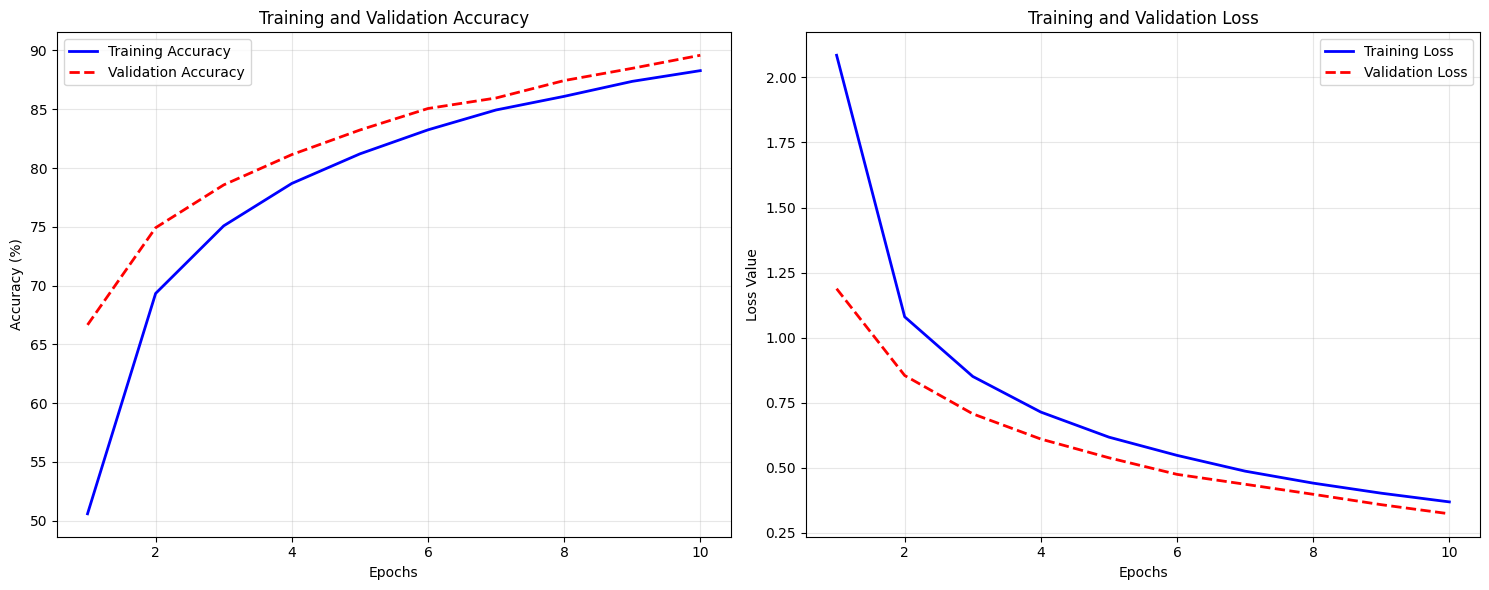

In [16]:
plot_training_history(history)

# **Step 8: Confusion Matrix and Scoring**

In [17]:
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_final_model(model, test_loader, class_names):
    model.load_state_dict(torch.load('best_pcsa_model.pth'))
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    # Detailed Scoring (P, R, F1) [cite: 180]
    print("\nClassification Report (Precision, Recall, F1):")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix for 12 Classes')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

In [18]:
import seaborn as sns

# Create the test loader
test_dataset = datasets.ImageFolder('/content/dataset_split/test', transform=val_transforms)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

# Get the class names directly from the dataset
class_names = test_dataset.classes


Classification Report (Precision, Recall, F1):
                                   precision    recall  f1-score   support

                Acalymma_vittatum       0.96      0.99      0.98       219
                  Achatina_fulica       1.00      1.00      1.00       256
                      Ampelophaga       0.96      0.99      0.97       279
                    Anasa_tristis       0.94      0.94      0.94       143
                           Aphids       0.92      0.88      0.90       247
               Armyworm_butterfly       0.67      0.40      0.50        25
             Armyworm_caterpillar       0.85      0.93      0.89       263
              Aulacophora_similis       0.97      1.00      0.99       212
        Beet spot flies_butterfly       0.85      0.48      0.61        92
      Beet spot flies_caterpillar       0.77      0.58      0.66       198
                Cicadella viridis       0.94      1.00      0.97       269
                     Cicadellidae       0.95      0

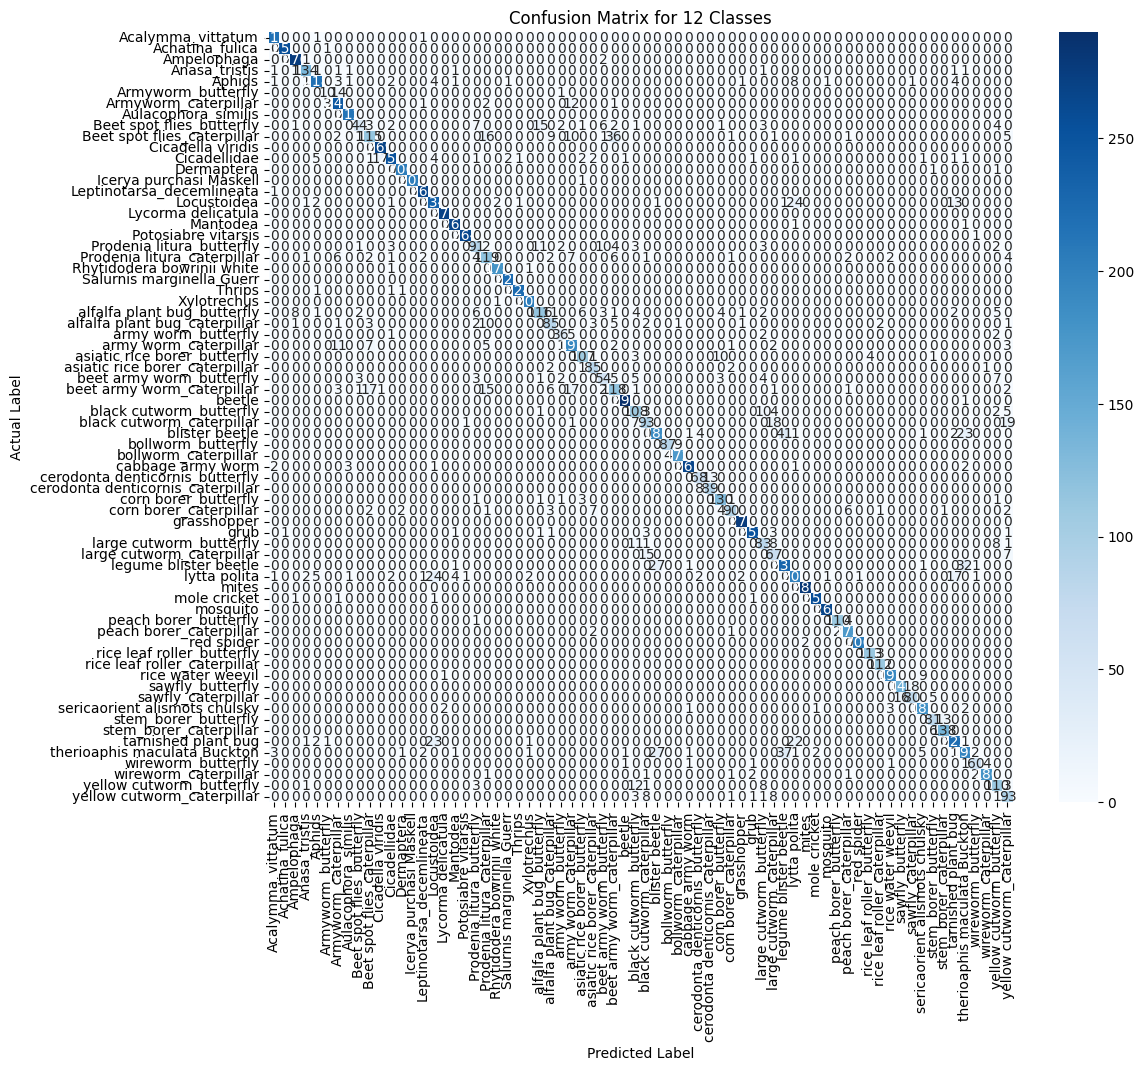

In [19]:
# This will load 'best_pcsa_model.pth', predict the test set, and plot the results
evaluate_final_model(model, test_loader, class_names)

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_large_model(model, test_loader):
    model.load_state_dict(torch.load('best_pcsa_model.pth'))
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    # 1. Print text report (keep this to look up specific class numbers)
    print("\nClassification Report:")
    # Removed target_names; it will default to numbers 0-78 which is much cleaner for 79 classes
    print(classification_report(y_true, y_pred))

    # 2. Compute and Normalize the Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-8) # added epsilon to prevent zero division

    # 3. Giant canvas for 79 classes
    plt.figure(figsize=(20, 16))

    # 4. CRITICAL CHANGES FOR 79 CLASSES:
    # - annot=False (CRITICAL: 79x79 numbers will completely black out the image)
    # - xticklabels/yticklabels=False (Stops 79 text strings from overlapping into a solid black line)
    sns.heatmap(
        cm_normalized,
        annot=False,      # Turn off numbers completely
        cmap='viridis',   # 'viridis' or 'magma' often show fine-grained errors better than Blues
        xticklabels=False, # Hide labels so the plot can breathe
        yticklabels=False,
        cbar_kws={'label': 'Accuracy Proportion (0.0 to 1.0)'}
    )

    plt.title('Confusion Matrix Heatmap (79 Classes)', fontsize=20, pad=20)
    plt.ylabel('Actual Classes (0 to 78)', fontsize=14)
    plt.xlabel('Predicted Classes (0 to 78)', fontsize=14)

    plt.tight_layout()
    plt.show()


Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       219
           1       1.00      1.00      1.00       256
           2       0.96      0.99      0.97       279
           3       0.94      0.94      0.94       143
           4       0.92      0.88      0.90       247
           5       0.67      0.40      0.50        25
           6       0.85      0.93      0.89       263
           7       0.97      1.00      0.99       212
           8       0.85      0.48      0.61        92
           9       0.77      0.58      0.66       198
          10       0.94      1.00      0.97       269
          11       0.95      0.86      0.90       294
          12       0.98      0.99      0.99       208
          13       1.00      1.00      1.00       206
          14       0.97      1.00      0.99       268
          15       0.80      0.84      0.82       280
          16       0.99      1.00      0.99       271
   

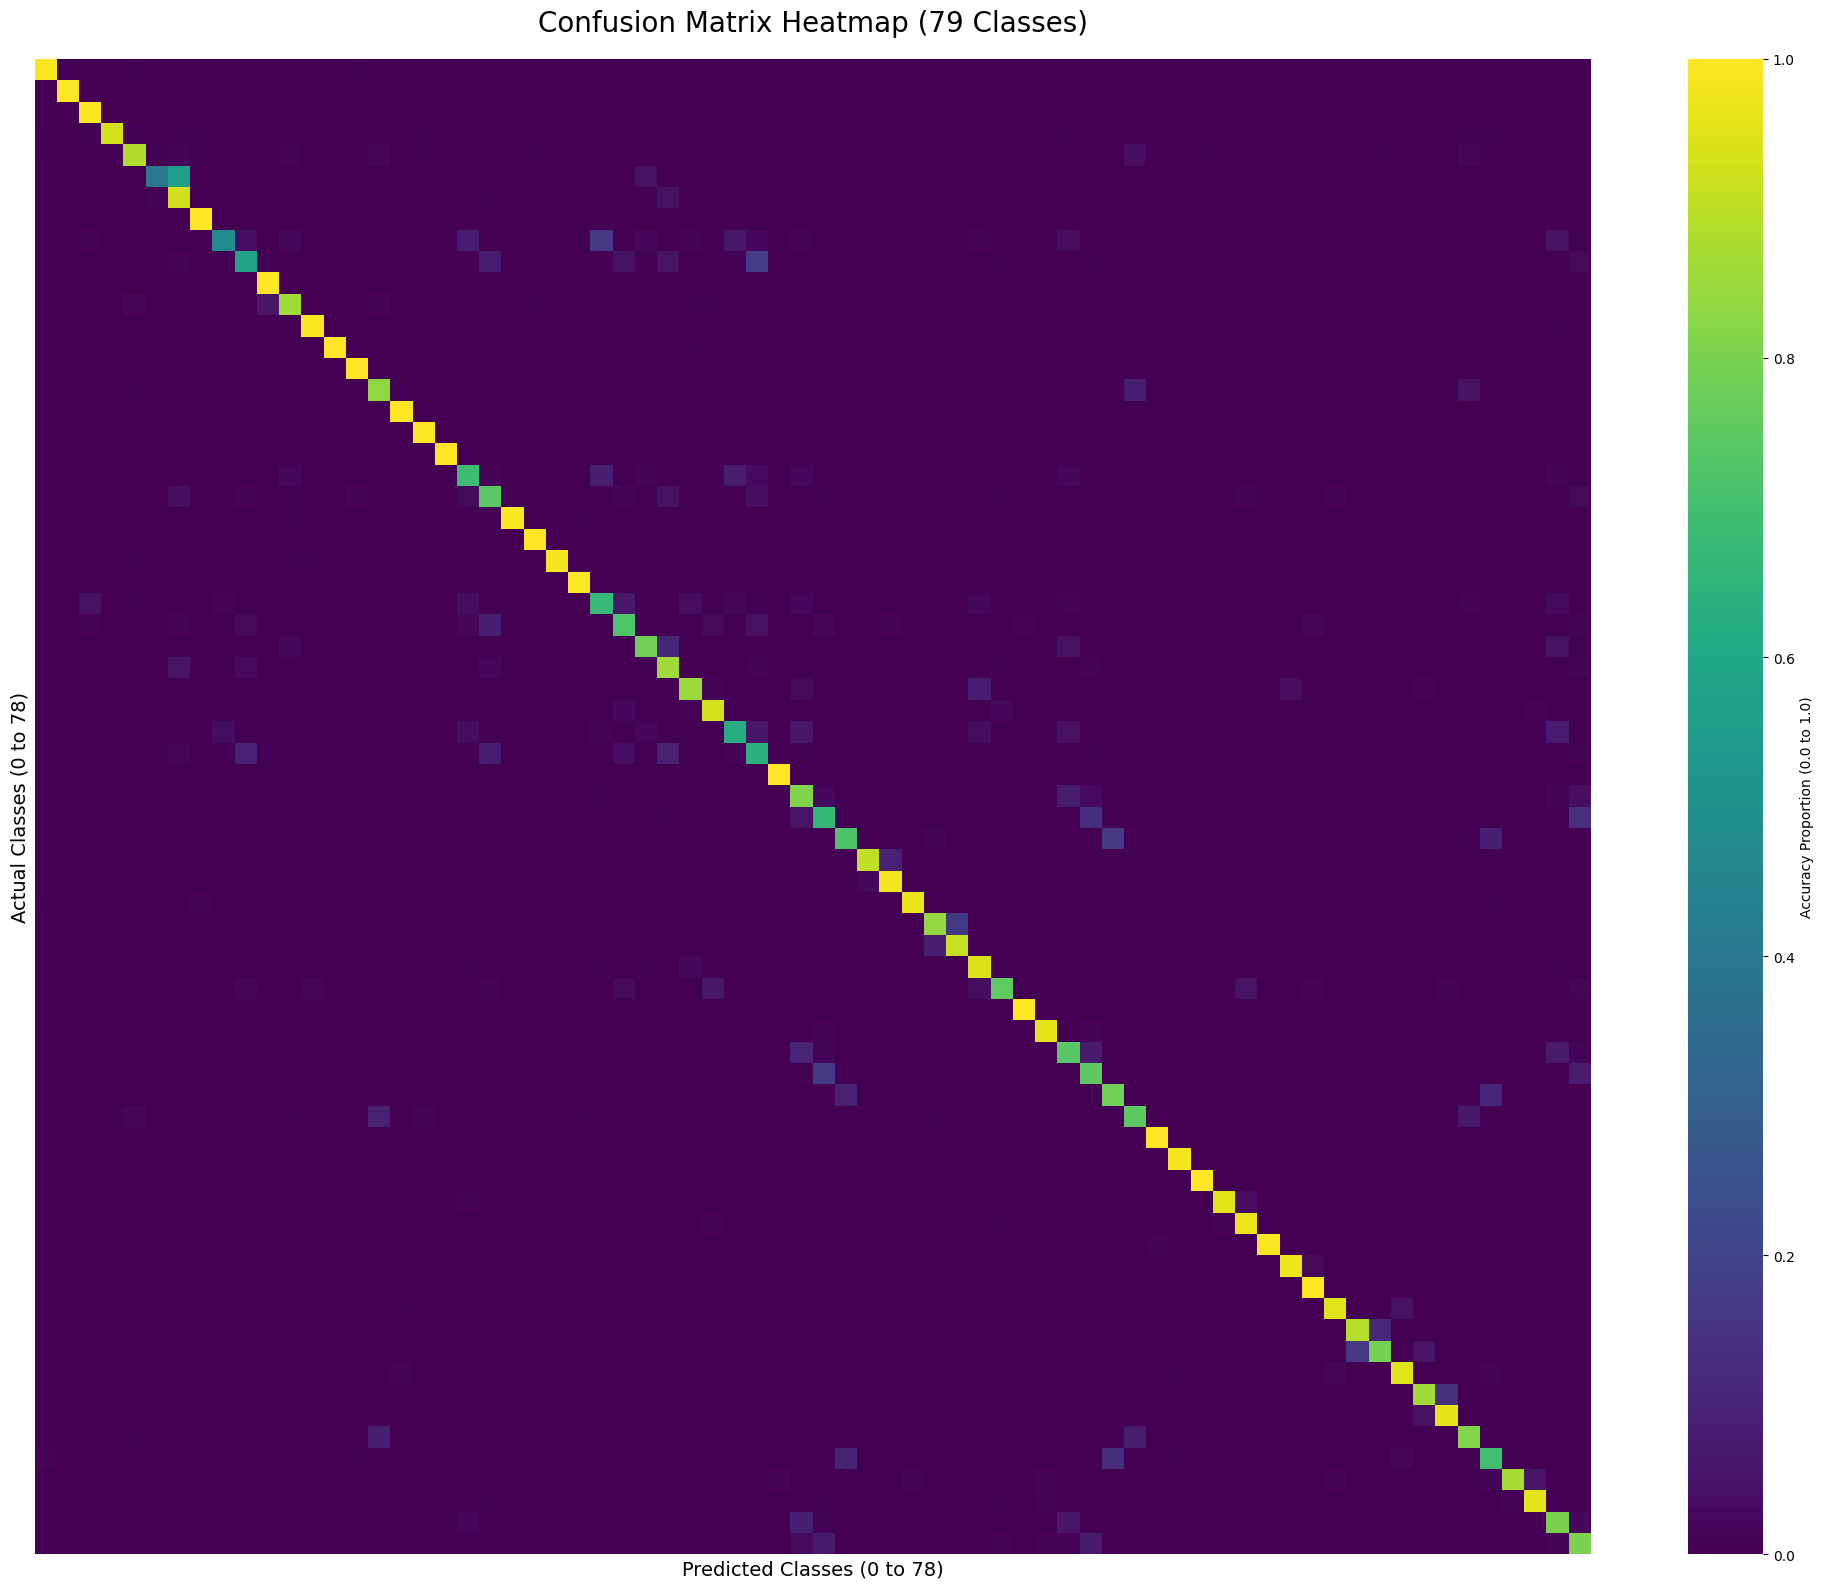

In [23]:
evaluate_large_model(model, test_loader)

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_massive_model(model, test_loader, class_names):
    model.load_state_dict(torch.load('best_pcsa_model.pth'))
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    # Standard text classification report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Compute raw confusion matrix (counts)
    cm = confusion_matrix(y_true, y_pred)

    # 1. HUGE canvas size to physically separate 79 classes
    fig, ax = plt.subplots(figsize=(45, 35))

    # 2. Plot with tiny text and zero spacing borders
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',          # Keeps raw numbers. Change to '.2f' if using normalized cm
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        linewidths=0.1,    # Adds a very thin line between cells to visually separate them
        linecolor='lightgray',
        annot_kws={"size": 7, "weight": "bold"}, # Makes internal numbers tiny but sharp
        cbar_kws={'shrink': 0.5} # Prevents the colorbar from dominating the height
    )

    # 3. Style the Title and Axis Labels
    plt.title('Complete Confusion Matrix (79 Classes)', fontsize=28, pad=30)
    plt.ylabel('Actual Label', fontsize=22)
    plt.xlabel('Predicted Label', fontsize=22)

    # 4. Rotate labels and shrink text so 79 words fit alongside each other
    plt.xticks(rotation=90, ha='center', fontsize=7) # 90 degrees vertical is best for 79 items
    plt.yticks(rotation=0, fontsize=7)

    plt.tight_layout()

    # 5. CRITICAL: Save as a high-res file.
    # Your Jupyter/IDE window will scale this down, making it look blurry.
    # Open this saved file directly on your computer and zoom in to read it perfectly!
    plt.savefig('massive_confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.savefig('massive_confusion_matrix.pdf', bbox_inches='tight') # PDF is infinitely zoomable

    plt.show()


Classification Report:
                                   precision    recall  f1-score   support

                Acalymma_vittatum       0.96      0.99      0.98       219
                  Achatina_fulica       1.00      1.00      1.00       256
                      Ampelophaga       0.96      0.99      0.97       279
                    Anasa_tristis       0.94      0.94      0.94       143
                           Aphids       0.92      0.88      0.90       247
               Armyworm_butterfly       0.67      0.40      0.50        25
             Armyworm_caterpillar       0.85      0.93      0.89       263
              Aulacophora_similis       0.97      1.00      0.99       212
        Beet spot flies_butterfly       0.85      0.48      0.61        92
      Beet spot flies_caterpillar       0.77      0.58      0.66       198
                Cicadella viridis       0.94      1.00      0.97       269
                     Cicadellidae       0.95      0.86      0.90       294


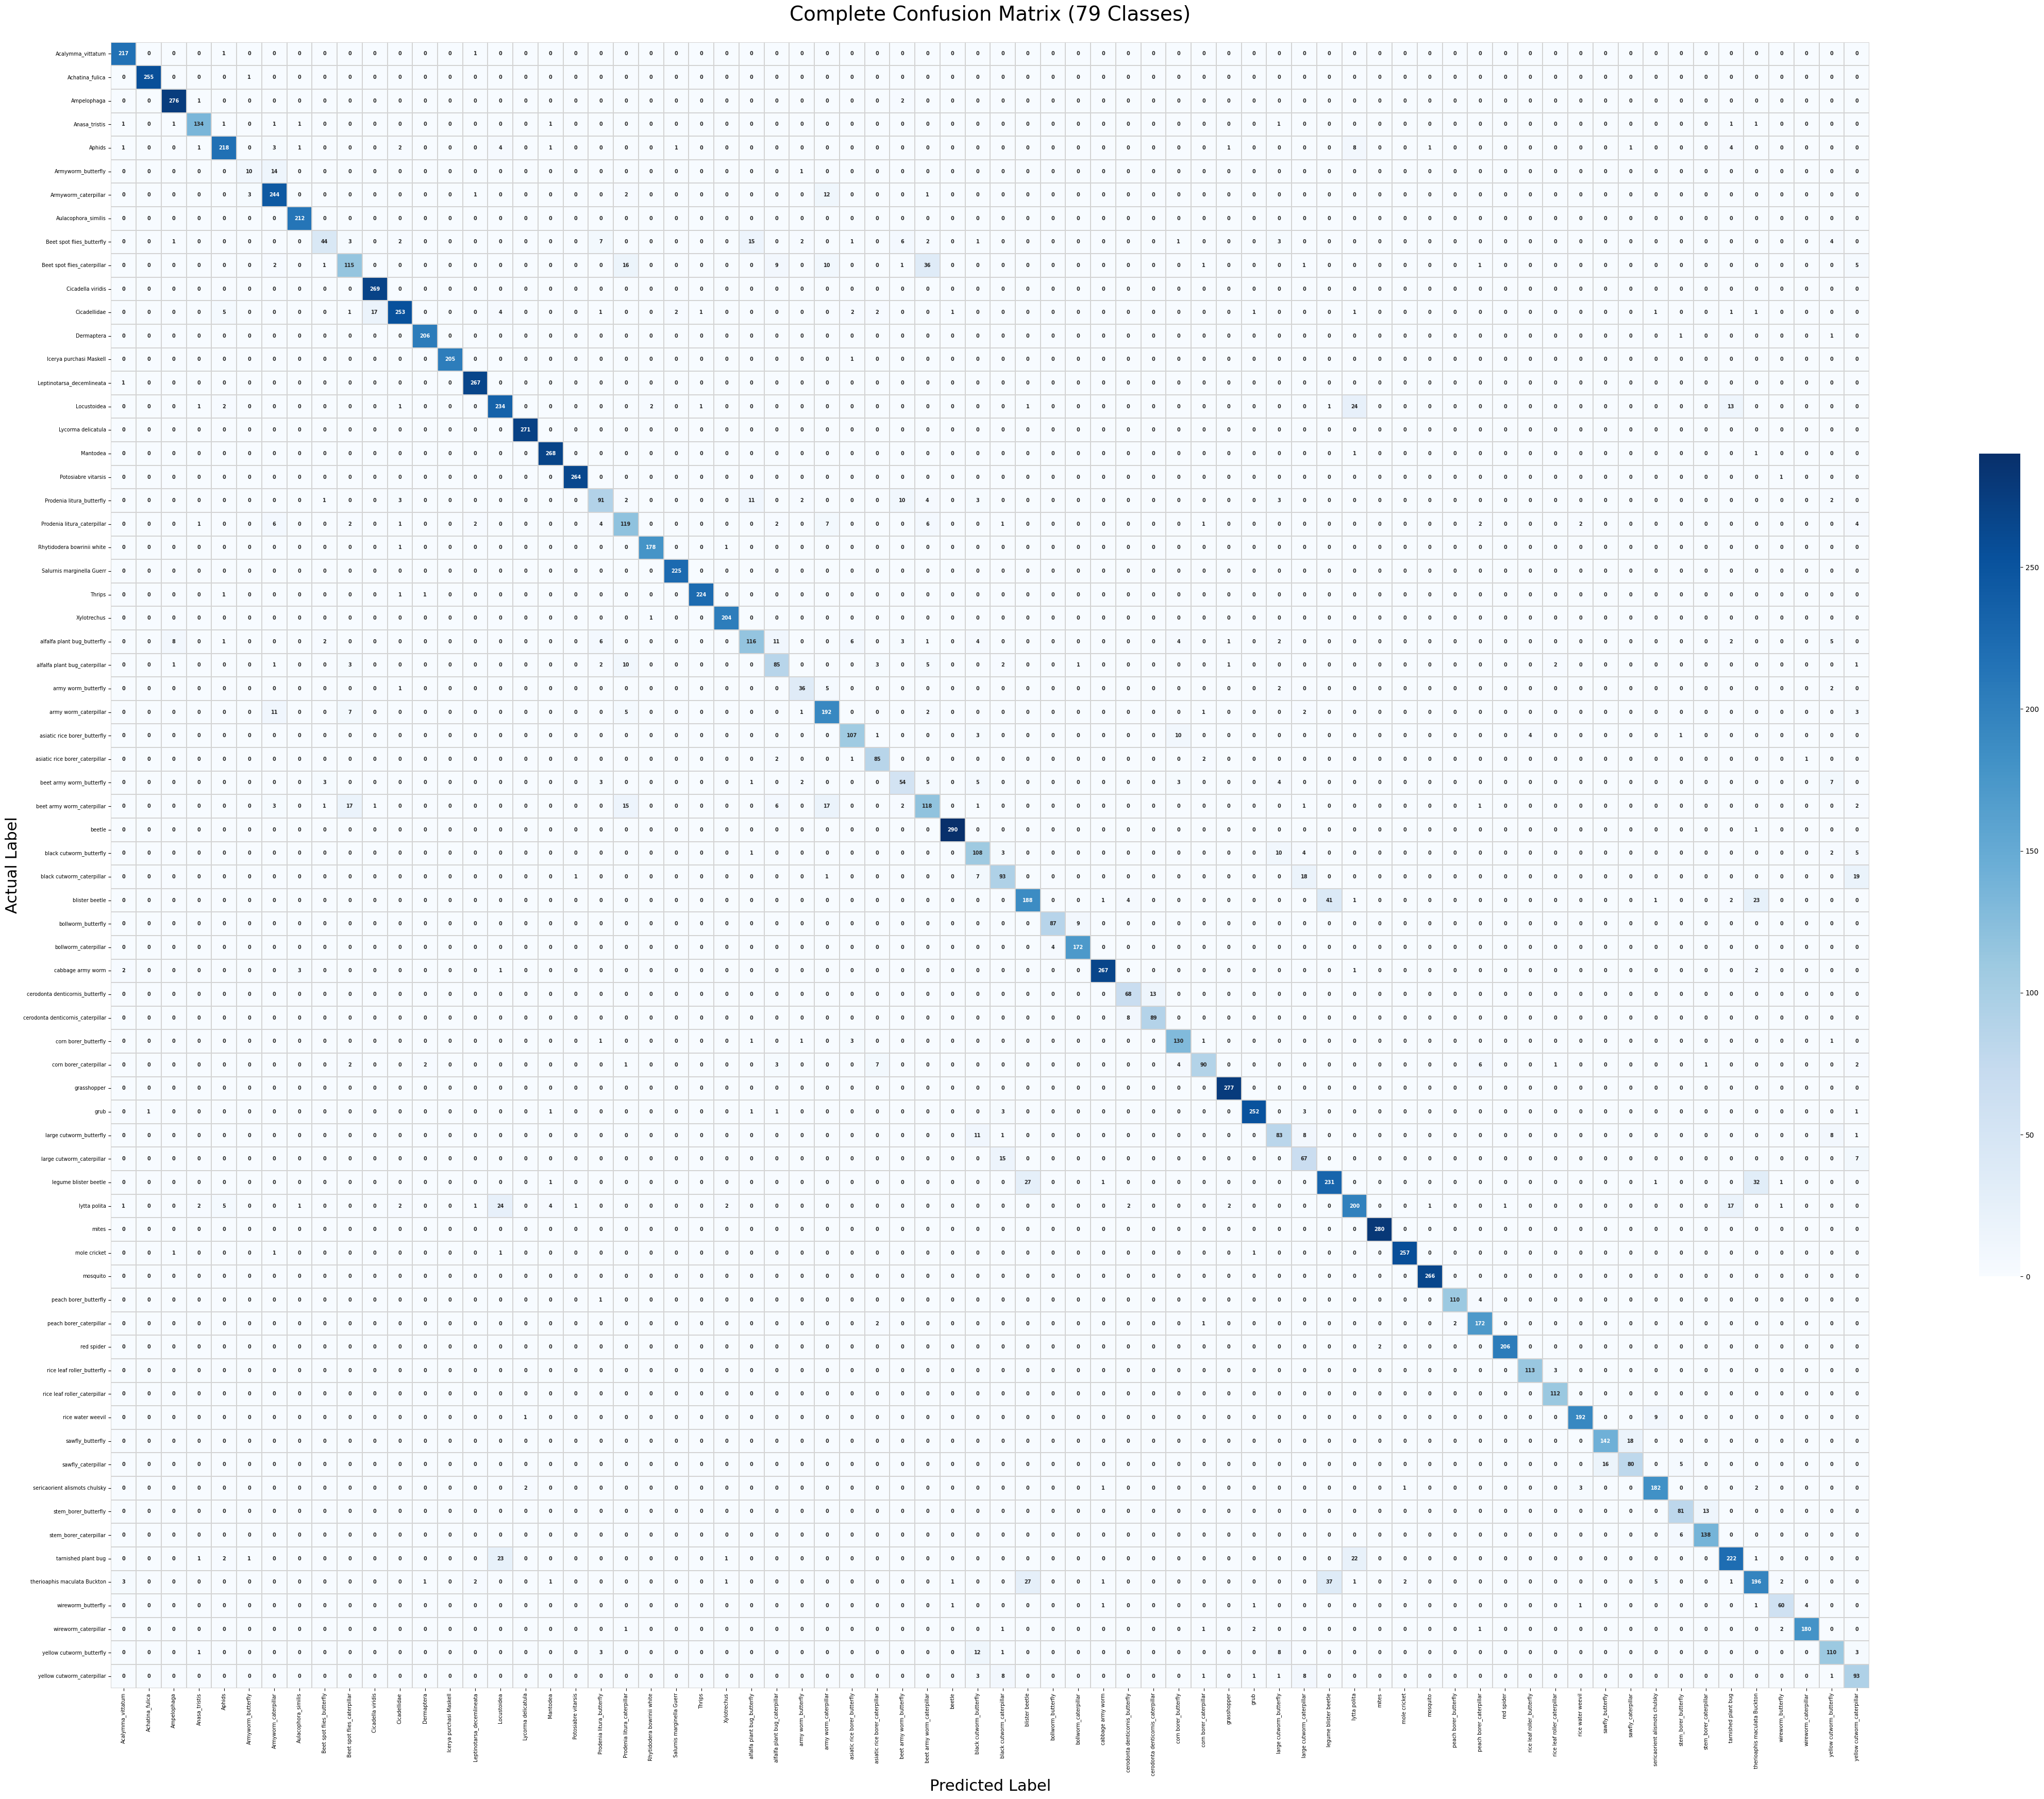

In [27]:
evaluate_massive_model(model, test_loader, class_names)

In [28]:
pip install grad-cam matplotlib numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 60.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl size=44286 sha256=f5d28585f42c291e41ccc9769ff5d3a52c35ef1d5f887994ed566de24bd9550e
  Stored in directory: /root/.cache/pip/wheels/fb/3b/09/2afc520f3d69bc26ae6bd87416759c820a3f7d05c1a077bbf6
Successfully built grad-cam


In [29]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

def generate_grid_cam_all_classes(model, test_loader, class_names, target_layer):
    """
    Finds one representative sample for each of the 79 classes,
    computes its Grad-CAM visual activation map, and plots them in a giant scannable grid.

    Args:
        model: Your trained PyTorch neural network.
        test_loader: Data loader containing the evaluation images.
        class_names: List of your 79 long insect class strings.
        target_layer: The final conv layer block of your network.
                      e.g., model.layer4[-1] (for ResNet) or model.features[-1] (for VGG)
    """
    model.load_state_dict(torch.load('best_pcsa_model.pth', map_location=device))
    model.eval()

    # 1. Initialize the PyTorch Grad-CAM controller
    cam = GradCAM(model=model, target_layers=[target_layer])

    # Dictionary to keep track of one raw image tensor per class index
    class_samples = {}

    print("Scanning test loader to grab one clean sample per class...")
    with torch.no_grad():
        for inputs, labels in test_loader:
            for i in range(inputs.size(0)):
                label_idx = labels[i].item()
                if label_idx not in class_samples:
                    class_samples[label_idx] = inputs[i]
                if len(class_samples) == len(class_names):
                    break
            if len(class_samples) == len(class_names):
                break

    # 2. Setup the Canvas Grid dimensions (16 rows x 5 columns fits 80 total slots)
    num_classes = len(class_names)
    rows = 16
    cols = 5
    fig, axes = plt.subplots(rows, cols, figsize=(25, 75)) # Massively vertical for crisp visibility
    axes = axes.flatten() # Flatten matrix to index via a singular tracking integer

    print("Processing Grad-CAM overlays across all 79 classes...")
    for class_idx in range(num_classes):
        ax = axes[class_idx]

        if class_idx in class_samples:
            # Reconstruct background tensor back into an inference batch
            img_tensor = class_samples[class_idx].unsqueeze(0).to(device)

            # Convert raw input tensor back to a standard printable RGB float array [0, 1]
            rgb_img = class_samples[class_idx].cpu().permute(1, 2, 0).numpy()
            # Normalize min/max if your loader contains standard transforms (e.g., Imagenet mean/std)
            rgb_img = (rgb_img - rgb_img.min()) / (rgb_img.max() - rgb_img.min() + 1e-8)

            # Target the specific logit index for evaluation
            targets = [ClassifierOutputTarget(class_idx)]

            # Generate the raw grayscale activation map mask
            grayscale_cam = cam(input_tensor=img_tensor, targets=targets)[0, :]

            # Superimpose heat overlay onto original RGB values
            cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

            # Plot inside sub-grid target slot
            ax.imshow(cam_image)
            ax.set_title(f"[{class_idx}] {class_names[class_idx][:30]}...", fontsize=10, weight='bold')
        else:
            ax.text(0.5, 0.5, f"Missing Sample\nClass {class_idx}", ha='center', va='center')

        ax.axis('off') # Hide tick markings to keep visual layout clear

    # Disable remaining empty subplots on row 16
    for blank_idx in range(num_classes, len(axes)):
        axes[blank_idx].axis('off')

    plt.tight_layout()

    # Save high resolution layout so you can zoom in and inspect micro textures
    print("Saving Grid-CAM visualizations...")
    plt.savefig('insect_grid_cam_hd.png', dpi=200, bbox_inches='tight')
    plt.show()

# --- HOW TO DEPLOY THE CELL ---
# Identify your model's target conv layer!
# Common options depending on architecture:
# - ResNet50:     model.layer4[-1]
# - EfficientNet: model.features[-1]
# - MobileNetV3:  model.features[-1]

# Example Target Execution call (Uncomment and replace 'model.layer4[-1]' with your specific architecture target layer):
# generate_grid_cam_all_classes(model, test_loader, class_names, target_layer=model.layer4[-1])